In [3]:
%pip -q install -U kagglehub ultralytics gradio opencv-python-headless scikit-learn pyyaml


In [4]:
from pathlib import Path
import os, random, shutil, tempfile, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import yaml
import torch
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc
from IPython.display import display, Markdown, Image as IPImage

SEED = 42
MAX_IMAGES = 4000       # None = весь train_images
EPOCHS = 20
IMAGE_SIZE = 640
BATCH_SIZE = 8          # при ошибке CUDA out of memory уменьшите до 4
MODEL_WEIGHTS = 'yolo11n.pt'
MIN_COMPONENT_AREA = 10 # отфильтровать шумовые области маски
CLASS_NAMES = {i: f'Дефект {i+1}' for i in range(4)}
WORK_DIR = Path('/content/severstal_yolo')
DATA_DIR = WORK_DIR / 'dataset'
RUN_DIR = WORK_DIR / 'runs'

random.seed(SEED)
np.random.seed(SEED)
print('PyTorch:', torch.__version__, '| CUDA:', torch.cuda.is_available())
if not torch.cuda.is_available():
    warnings.warn('GPU не найден. Обучение на CPU может быть очень долгим.')


PyTorch: 2.14.1+cu130 | CUDA: True


In [5]:
# Выберите источник. Для своих файлов замените путь на реальный путь к папке или zip.
DATA_SOURCE = 'kaggle'  # 'kaggle' или 'local'
LOCAL_DATA_PATH = '/content/drive/MyDrive/severstal-steel-defect-detection'

if DATA_SOURCE == 'local':
    if LOCAL_DATA_PATH.startswith('/content/drive/'):
        from google.colab import drive
        drive.mount('/content/drive')
    download_path = Path(LOCAL_DATA_PATH)
    if not download_path.exists():
        raise FileNotFoundError(f'Указанный путь не найден: {download_path}')
elif DATA_SOURCE == 'kaggle':
    try:
        from google.colab import userdata
        token = userdata.get('KAGGLE_API_TOKEN')
        if token:
            os.environ['KAGGLE_API_TOKEN'] = token
    except Exception:
        pass
    try:
        download_path = Path(kagglehub.competition_download('severstal-steel-defect-detection'))
    except Exception as exc:
        raise RuntimeError(
            'Не удалось скачать соревнование. Войдите в Kaggle, примите правила '
            'и добавьте KAGGLE_API_TOKEN в Secrets Colab. '
            'Либо выберите DATA_SOURCE="local" и укажите скачанные файлы.'
        ) from exc
else:
    raise ValueError('DATA_SOURCE должен быть kaggle или local')

print('Источник данных:', download_path)
if download_path.is_dir():
    print('Верхний уровень:', [p.name for p in download_path.iterdir()][:20])


100%|██████████| 1.57G/1.57G [00:25<00:00, 66.9MB/s]

Extracting files...


Источник данных: /root/.cache/kagglehub/competitions/severstal-steel-defect-detection
Верхний уровень: ['sample_submission.csv', 'train.csv', 'train_images', 'test_images']


In [6]:
# kagglehub обычно распаковывает архив, но этот блок поддерживает и zip-файлы.
import zipfile

def find_dataset(root):
    if root.is_file() and root.suffix.lower() == '.zip':
        target = WORK_DIR / 'kaggle_unpacked' / root.stem
        if not target.exists():
            target.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(root) as zf:
                zf.extractall(target)
        root = target
    csv_files = list(root.rglob('train.csv'))
    image_dirs = [p for p in root.rglob('train_images') if p.is_dir()]
    if csv_files and image_dirs:
        return csv_files[0], image_dirs[0]
    for archive in root.rglob('*.zip'):
        target = WORK_DIR / 'kaggle_unpacked' / archive.stem
        if not target.exists():
            target.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(archive) as zf:
                zf.extractall(target)
        csv_files = list(target.rglob('train.csv'))
        image_dirs = [p for p in target.rglob('train_images') if p.is_dir()]
        if csv_files and image_dirs:
            return csv_files[0], image_dirs[0]
    raise FileNotFoundError('Не найдены train.csv и train_images в загруженных файлах.')

csv_path, images_dir = find_dataset(download_path)
print('Разметка:', csv_path)
print('Изображения:', images_dir)


Разметка: /root/.cache/kagglehub/competitions/severstal-steel-defect-detection/train.csv
Изображения: /root/.cache/kagglehub/competitions/severstal-steel-defect-detection/train_images


In [7]:
raw = pd.read_csv(csv_path)
if {'ImageId', 'ClassId', 'EncodedPixels'} <= set(raw.columns):
    ann = raw[['ImageId', 'ClassId', 'EncodedPixels']].copy()
elif {'ImageId_ClassId', 'EncodedPixels'} <= set(raw.columns):
    parts = raw['ImageId_ClassId'].str.rsplit('_', n=1, expand=True)
    ann = pd.DataFrame({'ImageId': parts[0], 'ClassId': parts[1],
                        'EncodedPixels': raw['EncodedPixels']})
else:
    raise ValueError(f'Неизвестный формат train.csv: {list(raw.columns)}')
ann['ClassId'] = ann['ClassId'].astype(int)
assert set(ann['ClassId'].unique()) <= {1, 2, 3, 4}
ann['EncodedPixels'] = ann['EncodedPixels'].fillna('').astype(str).str.strip()
ann = ann[ann['EncodedPixels'].ne('')]

image_paths = sorted(images_dir.glob('*.jpg'))
if not image_paths:
    image_paths = sorted(images_dir.glob('*.JPG'))
assert image_paths, 'В train_images нет JPG-файлов'
by_image = {name: group for name, group in ann.groupby('ImageId')}

print('Строк CSV:', len(raw), '| изображений:', len(image_paths),
      '| изображений с дефектами:', len(by_image))
display(ann.head())
counts = ann.groupby('ClassId')['ImageId'].nunique().reindex(range(1, 5), fill_value=0)
display(pd.DataFrame({'Класс': [f'Дефект {i}' for i in range(1,5)],
                      'Изображений с классом': counts.values}))


Строк CSV: 7095 | изображений: 12568 | изображений с дефектами: 6666


,ImageId,ClassId,EncodedPixels
0,0002cc93b.jpg,1,29102 12 29346 24 29602 24 29858 24 30114 24 3...
1,0007a71bf.jpg,3,18661 28 18863 82 19091 110 19347 110 19603 11...
2,000a4bcdd.jpg,1,37607 3 37858 8 38108 14 38359 20 38610 25 388...
3,000f6bf48.jpg,4,131973 1 132228 4 132483 6 132738 8 132993 11 ...
4,0014fce06.jpg,3,229501 11 229741 33 229981 55 230221 77 230468...


,Класс,Изображений с классом
0,Дефект 1,897
1,Дефект 2,247
2,Дефект 3,5150
3,Дефект 4,801


In [8]:
# Стратификационный ярлык: редчайший класс на снимке, иначе 0.
rarity = counts.to_dict()
def stratum(path):
    group = by_image.get(path.name)
    if group is None:
        return 0
    return min(set(group['ClassId']), key=lambda c: (rarity[c], c))

all_strata = np.array([stratum(p) for p in image_paths])
if MAX_IMAGES is not None and MAX_IMAGES < len(image_paths):
    if MAX_IMAGES < 100:
        raise ValueError('MAX_IMAGES должен быть не меньше 100.')
    selected, _ = train_test_split(
        np.arange(len(image_paths)), train_size=MAX_IMAGES,
        stratify=all_strata, random_state=SEED)
    selected_paths = [image_paths[i] for i in selected]
else:
    selected_paths = image_paths

strata = [stratum(p) for p in selected_paths]
trainval, test_paths = train_test_split(
    selected_paths, test_size=0.15, stratify=strata, random_state=SEED)
train_paths, val_paths = train_test_split(
    trainval, test_size=0.15/0.85,
    stratify=[stratum(p) for p in trainval], random_state=SEED)
splits = {'train': train_paths, 'val': val_paths, 'test': test_paths}
assert not (set(train_paths) & set(val_paths) | set(train_paths) & set(test_paths)
            | set(val_paths) & set(test_paths))
for name, paths in splits.items():
    print(name, len(paths), pd.Series([stratum(p) for p in paths]).value_counts().sort_index().to_dict())


train 2800 {0: 1314, 1: 192, 2: 54, 3: 1061, 4: 179}
val 600 {0: 282, 1: 41, 2: 12, 3: 227, 4: 38}
test 600 {0: 282, 1: 41, 2: 12, 3: 227, 4: 38}


In [9]:
def decode_rle(rle, height, width):
    """Kaggle RLE: старт 1-based, обход по столбцам (Fortran order)."""
    tokens = np.asarray([int(v) for v in str(rle).split()], dtype=np.int64)
    if len(tokens) % 2:
        raise ValueError('Некорректная RLE: нечётное число значений')
    flat = np.zeros(height * width, dtype=np.uint8)
    for start, length in tokens.reshape(-1, 2):
        start -= 1
        if start < 0 or start + length > flat.size:
            raise ValueError('RLE выходит за границы изображения')
        flat[start:start+length] = 1
    return flat.reshape((height, width), order='F')

def mask_to_yolo_boxes(mask, class_id, min_area=MIN_COMPONENT_AREA):
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    height, width = mask.shape
    lines = []
    for i in range(1, n):
        x, y, w, h, area = stats[i]
        if area < min_area:
            continue
        lines.append(f'{class_id-1} {(x+w/2)/width:.6f} {(y+h/2)/height:.6f} '
                     f'{w/width:.6f} {h/height:.6f}')
    return lines

# Мини-проверка геометрии: два пикселя в одном столбце должны остаться рядом.
assert np.array_equal(decode_rle('2 2', 4, 3),
                      np.array([[0,0,0],[1,0,0],[1,0,0],[0,0,0]], dtype=np.uint8))
assert len(mask_to_yolo_boxes(decode_rle('2 2', 4, 3), 1, min_area=1)) == 1
print('Проверка декодирования RLE пройдена.')


Проверка декодирования RLE пройдена.


In [10]:
# Создание labels и ссылок на исходные JPG (при невозможности — копий).
for split, paths in splits.items():
    img_out = DATA_DIR / 'images' / split
    lab_out = DATA_DIR / 'labels' / split
    img_out.mkdir(parents=True, exist_ok=True)
    lab_out.mkdir(parents=True, exist_ok=True)
    written_boxes = 0
    for source in paths:
        target = img_out / source.name
        if not target.exists():
            try:
                target.symlink_to(source)
            except OSError:
                shutil.copy2(source, target)
        group = by_image.get(source.name)
        lines = []
        if group is not None:
            image = cv2.imread(str(source))
            if image is None:
                raise ValueError(f'Не удалось открыть {source}')
            height, width = image.shape[:2]
            for row in group.itertuples(index=False):
                mask = decode_rle(row.EncodedPixels, height, width)
                lines.extend(mask_to_yolo_boxes(mask, row.ClassId))
        (lab_out / f'{source.stem}.txt').write_text('\n'.join(lines), encoding='utf-8')
        written_boxes += len(lines)
    print(f'{split}: {len(paths)} изображений, {written_boxes} рамок')

yaml_path = WORK_DIR / 'steel.yaml'
config = {'path': str(DATA_DIR), 'train': 'images/train', 'val': 'images/val',
          'test': 'images/test', 'names': CLASS_NAMES}
yaml_path.write_text(yaml.safe_dump(config, allow_unicode=True, sort_keys=False), encoding='utf-8')
print(yaml_path.read_text(encoding='utf-8'))


train: 2800 изображений, 4469 рамок
val: 600 изображений, 905 рамок
test: 600 изображений, 918 рамок
path: /content/severstal_yolo/dataset
train: images/train
val: images/val
test: images/test
names:
  0: Дефект 1
  1: Дефект 2
  2: Дефект 3
  3: Дефект 4



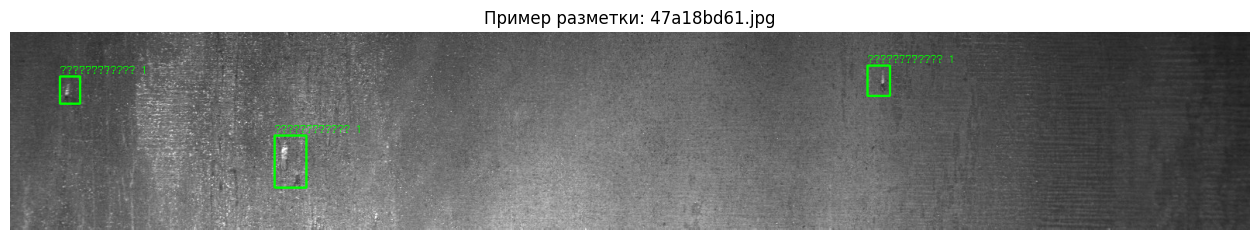

In [11]:
# Визуальная проверка конвертации: исходное фото и YOLO-рамки.
example = next((p for p in train_paths if (DATA_DIR/'labels/train'/f'{p.stem}.txt').read_text().strip()), None)
assert example is not None, 'В обучающей выборке нет размеченных дефектов'
view = cv2.imread(str(example))
h, w = view.shape[:2]
for line in (DATA_DIR/'labels/train'/f'{example.stem}.txt').read_text().splitlines():
    cls, xc, yc, bw, bh = map(float, line.split())
    x1, y1 = int((xc-bw/2)*w), int((yc-bh/2)*h)
    x2, y2 = int((xc+bw/2)*w), int((yc+bh/2)*h)
    cv2.rectangle(view, (x1,y1), (x2,y2), (0,255,0), 2)
    cv2.putText(view, CLASS_NAMES[int(cls)], (x1,max(15,y1-4)),
                cv2.FONT_HERSHEY_SIMPLEX, .45, (0,255,0), 1)
plt.figure(figsize=(16,4))
plt.imshow(cv2.cvtColor(view, cv2.COLOR_BGR2RGB))
plt.axis('off'); plt.title(f'Пример разметки: {example.name}'); plt.show()


In [12]:
from ultralytics import YOLO

model = YOLO(MODEL_WEIGHTS)
train_result = model.train(
    data=str(yaml_path), epochs=EPOCHS, imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE, optimizer='AdamW', lr0=0.001, lrf=0.01,
    patience=7, seed=SEED, deterministic=True,
    device=0 if torch.cuda.is_available() else 'cpu', workers=2,
    project=str(RUN_DIR), name='steel_yolo11n', exist_ok=True,
    plots=True, verbose=True,
)
BEST_WEIGHTS = RUN_DIR / 'steel_yolo11n' / 'weights' / 'best.pt'
assert BEST_WEIGHTS.exists(), 'После обучения не найден best.pt'
print('Лучшая модель:', BEST_WEIGHTS)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/severstal_yolo/steel.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
15,16,840.956,1.81990,1.76907,1.21386,0.48112,0.32943,0.35749,0.17224,1.74623,1.71927,1.18113,0.000258,0.000258,0.000258
16,17,893.341,1.83069,1.76659,1.20006,0.42547,0.36816,0.33454,0.16036,1.75850,1.71999,1.18261,0.000208,0.000208,0.000208
17,18,945.720,1.74465,1.72970,1.17261,0.49741,0.33890,0.36260,0.17284,1.73571,1.66605,1.15583,0.000159,0.000159,0.000159
18,19,998.599,1.75229,1.67867,1.17349,0.41804,0.41045,0.39133,0.18390,1.70679,1.61696,1.16222,0.000109,0.000109,0.000109
19,20,1051.550,1.75819,1.71719,1.18363,0.51813,0.36260,0.38441,0.18988,1.69460,1.61539,1.14933,0.000060,0.000060,0.000060


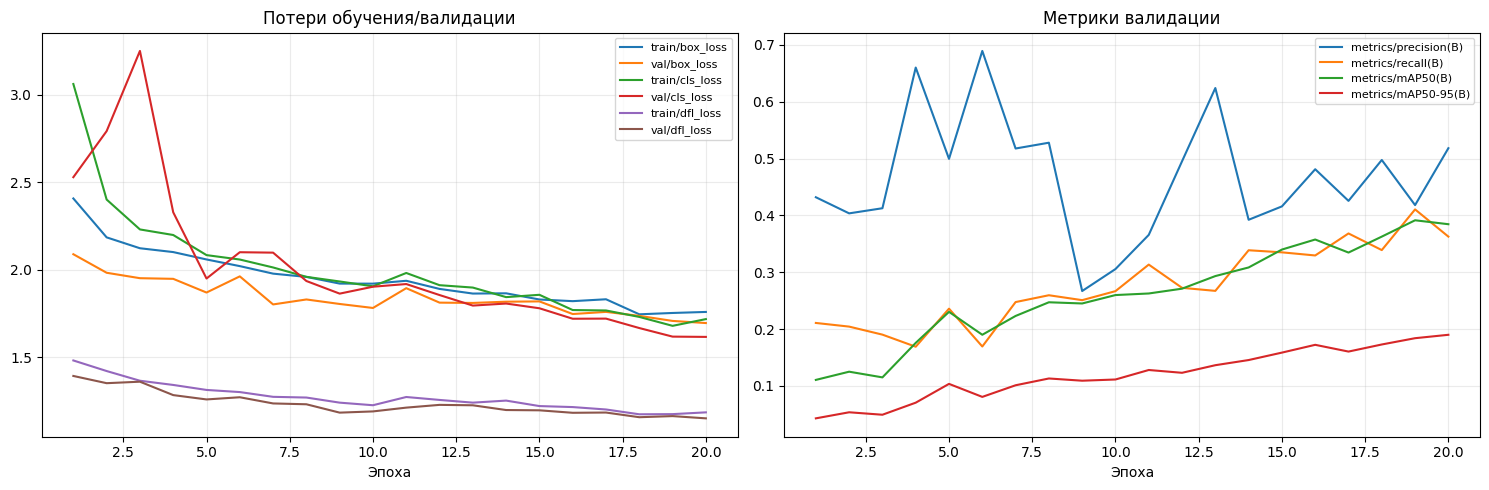

Лучшая эпоха по val mAP50-95: 21
Val mAP50: 0.384; val mAP50-95: 0.190
train/box_loss: 2.408 → 1.758 (снизилась)
val/box_loss: 2.088 → 1.695 (снизилась)
train/cls_loss: 3.062 → 1.717 (снизилась)
val/cls_loss: 2.529 → 1.615 (снизилась)


In [13]:
history = pd.read_csv(RUN_DIR / 'steel_yolo11n' / 'results.csv')
history.columns = history.columns.str.strip()
display(history.tail(5))

groups = [
    ['train/box_loss','val/box_loss','train/cls_loss','val/cls_loss',
     'train/dfl_loss','val/dfl_loss'],
    ['metrics/precision(B)','metrics/recall(B)',
     'metrics/mAP50(B)','metrics/mAP50-95(B)'],
]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, columns, title in zip(axes, groups, ['Потери обучения/валидации', 'Метрики валидации']):
    for col in columns:
        if col in history:
            ax.plot(history['epoch'], history[col], label=col)
    ax.set(xlabel='Эпоха', title=title)
    ax.grid(alpha=.25); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

best_row = history.loc[history['metrics/mAP50-95(B)'].idxmax()]
last_row = history.iloc[-1]
print(f"Лучшая эпоха по val mAP50-95: {int(best_row['epoch']) + 1}")
print(f"Val mAP50: {best_row['metrics/mAP50(B)']:.3f}; "
      f"val mAP50-95: {best_row['metrics/mAP50-95(B)']:.3f}")
for col in ['train/box_loss', 'val/box_loss', 'train/cls_loss', 'val/cls_loss']:
    if col in history:
        direction = 'снизилась' if last_row[col] < history.iloc[0][col] else 'выросла'
        print(f'{col}: {history.iloc[0][col]:.3f} → {last_row[col]:.3f} ({direction})')


Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1616.8±793.0 MB/s, size: 104.4 KB)
val: Scanning /content/severstal_yolo/dataset/labels/test... 600 images, 282 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 600/600 2.2Kit/s 0.3s
val: New cache created: /content/severstal_yolo/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 75/75 16.0it/s 4.7s
                   all        600        918      0.461      0.341      0.334      0.152
              Дефект 1         44        116      0.362      0.328      0.282      0.106
              Дефект 2         12         16      0.609     0.0625      0.161     0.0591
              Дефект 3        238        689      0.449      0.594       0.53      0.253
              Дефект 4         38         97     

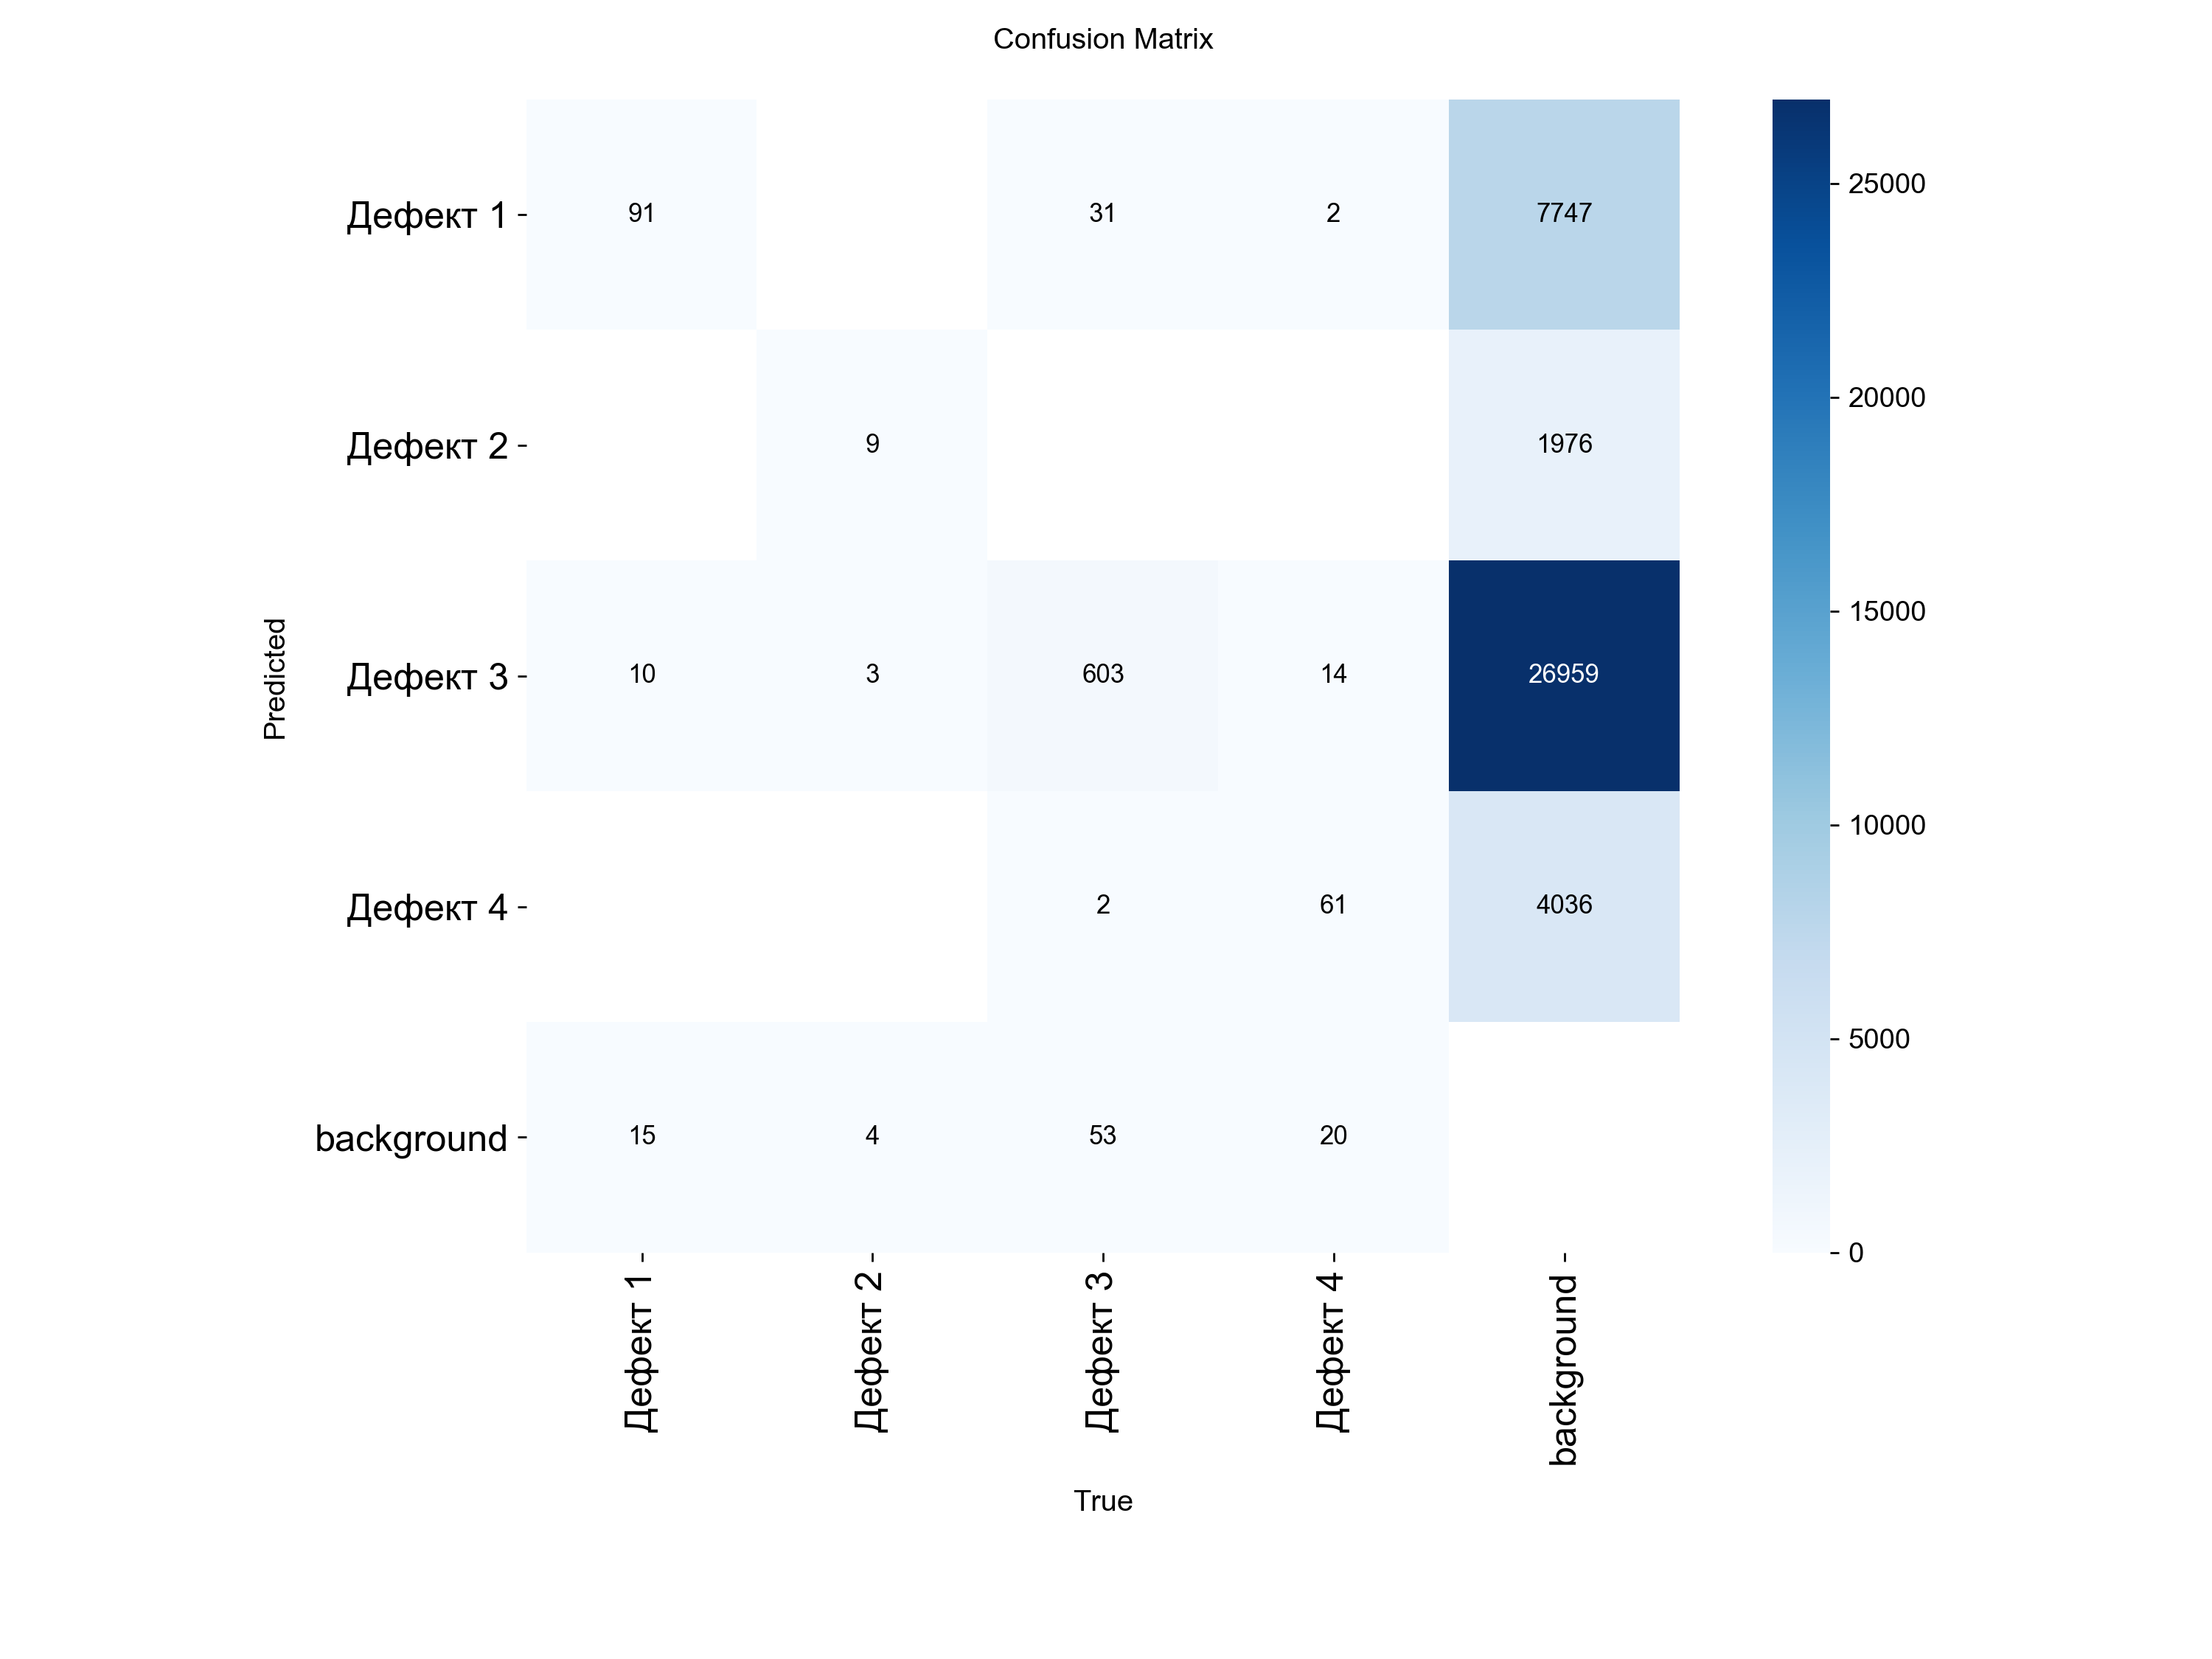

In [14]:
best_model = YOLO(str(BEST_WEIGHTS))
test_metrics = best_model.val(
    data=str(yaml_path), split='test', imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE, device=0 if torch.cuda.is_available() else 'cpu',
    project=str(RUN_DIR), name='test_evaluation', exist_ok=True,
    plots=True, conf=0.001,
)
p, r = float(test_metrics.box.mp), float(test_metrics.box.mr)
f1 = 2*p*r/(p+r) if p+r else 0.0
print(f'Test Precision={p:.4f}, Recall={r:.4f}, F1={f1:.4f}')
print(f'Test mAP@0.5={test_metrics.box.map50:.4f}, '
      f'mAP@0.5:0.95={test_metrics.box.map:.4f}')

eval_dir = RUN_DIR / 'test_evaluation'
for filename in ['PR_curve.png', 'F1_curve.png', 'confusion_matrix.png']:
    path = eval_dir / filename
    if path.exists():
        print(filename)
        display(IPImage(filename=str(path), width=750))


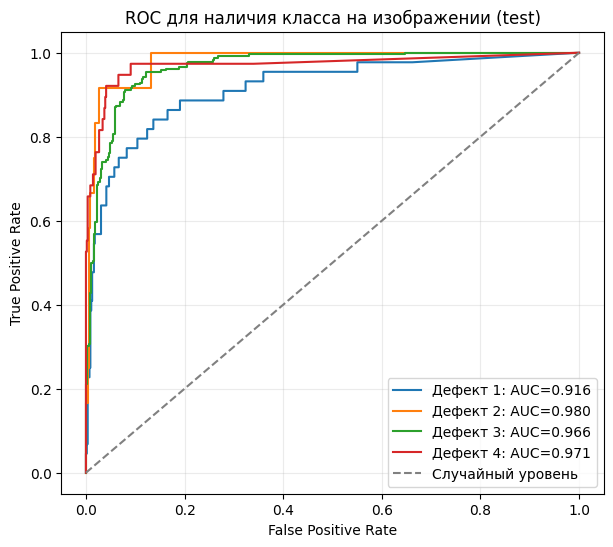

,Класс,AUC,Положительных изображений
0,Дефект 1,0.915999,44
1,Дефект 2,0.980442,12
2,Дефект 3,0.965818,238
3,Дефект 4,0.970804,38


In [15]:
truth = np.zeros((len(test_paths), 4), dtype=np.uint8)
scores = np.zeros((len(test_paths), 4), dtype=float)
detections = {}
for i, path in enumerate(test_paths):
    label_path = DATA_DIR / 'labels' / 'test' / f'{path.stem}.txt'
    for line in label_path.read_text().splitlines():
        truth[i, int(line.split()[0])] = 1

for i, path in enumerate(test_paths):
    result = best_model.predict(str(path), imgsz=IMAGE_SIZE, conf=0.001,
                                verbose=False)[0]
    detections[path.name] = result
    if result.boxes is not None and len(result.boxes):
        classes = result.boxes.cls.cpu().numpy().astype(int)
        confidences = result.boxes.conf.cpu().numpy()
        for class_id in range(4):
            values = confidences[classes == class_id]
            if len(values):
                scores[i, class_id] = values.max()

plt.figure(figsize=(7, 6))
auc_rows = []
for class_id in range(4):
    y = truth[:, class_id]
    if len(np.unique(y)) < 2:
        print(f'{CLASS_NAMES[class_id]}: ROC/AUC не определена — только один вид меток')
        continue
    fpr, tpr, _ = roc_curve(y, scores[:, class_id])
    class_auc = auc(fpr, tpr)
    auc_rows.append((CLASS_NAMES[class_id], class_auc, int(y.sum())))
    plt.plot(fpr, tpr, label=f'{CLASS_NAMES[class_id]}: AUC={class_auc:.3f}')
plt.plot([0,1], [0,1], '--', color='gray', label='Случайный уровень')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC для наличия класса на изображении (test)')
plt.grid(alpha=.25); plt.legend(); plt.show()
display(pd.DataFrame(auc_rows, columns=['Класс','AUC','Положительных изображений']))


In [16]:
def read_ground_truth(path, split='test'):
    img = cv2.imread(str(path))
    h, w = img.shape[:2]
    out = []
    label = DATA_DIR / 'labels' / split / f'{path.stem}.txt'
    for line in label.read_text().splitlines():
        c, xc, yc, bw, bh = map(float, line.split())
        out.append((int(c), np.array([(xc-bw/2)*w, (yc-bh/2)*h,
                                      (xc+bw/2)*w, (yc+bh/2)*h])))
    return out

def box_iou(a, b):
    left_top = np.maximum(a[:2], b[:2])
    right_bottom = np.minimum(a[2:], b[2:])
    intersection = np.prod(np.maximum(0, right_bottom-left_top))
    area_a = np.prod(np.maximum(0, a[2:]-a[:2]))
    area_b = np.prod(np.maximum(0, b[2:]-b[:2]))
    return intersection / max(area_a + area_b - intersection, 1e-9)

ground_truth = {p.name: read_ground_truth(p) for p in test_paths}
comparison = []
for threshold in [0.25, 0.50]:
    tp = fp = fn = 0
    for path in test_paths:
        gt = ground_truth[path.name]
        matched = set()
        result = detections[path.name]
        boxes = result.boxes
        if boxes is not None and len(boxes):
            pred = sorted(zip(boxes.cls.cpu().numpy().astype(int),
                              boxes.conf.cpu().numpy(), boxes.xyxy.cpu().numpy()),
                          key=lambda item: -item[1])
            for cls, conf, xyxy in pred:
                if conf < threshold:
                    continue
                candidates = [(j, box_iou(xyxy, gt_box))
                              for j, (gt_cls, gt_box) in enumerate(gt)
                              if j not in matched and gt_cls == cls]
                if candidates:
                    j, overlap = max(candidates, key=lambda item: item[1])
                    if overlap >= 0.5:
                        matched.add(j); tp += 1
                        continue
                fp += 1
        fn += len(gt) - len(matched)
    precision = tp/(tp+fp) if tp+fp else 0
    recall = tp/(tp+fn) if tp+fn else 0
    comparison.append({'Порог': threshold, 'TP': tp, 'FP': fp, 'FN': fn,
                       'Precision': precision, 'Recall': recall,
                       'F1': 2*precision*recall/(precision+recall) if precision+recall else 0})
display(pd.DataFrame(comparison))

indices = list(map(int, test_metrics.box.ap_class_index))
per_class = pd.DataFrame({
    'Класс': [CLASS_NAMES[i] for i in indices],
    'AP@0.5': test_metrics.box.ap50,
    'AP@0.5:0.95': test_metrics.box.ap,
})
display(per_class)


,Порог,TP,FP,FN,Precision,Recall,F1
0,0.25,417,224,501,0.650546,0.454248,0.534958
1,0.50,152,29,766,0.839779,0.165577,0.276615


,Класс,AP@0.5,AP@0.5:0.95
0,Дефект 1,0.282140,0.106268
1,Дефект 2,0.161272,0.059092
2,Дефект 3,0.529789,0.253209
3,Дефект 4,0.364358,0.189716


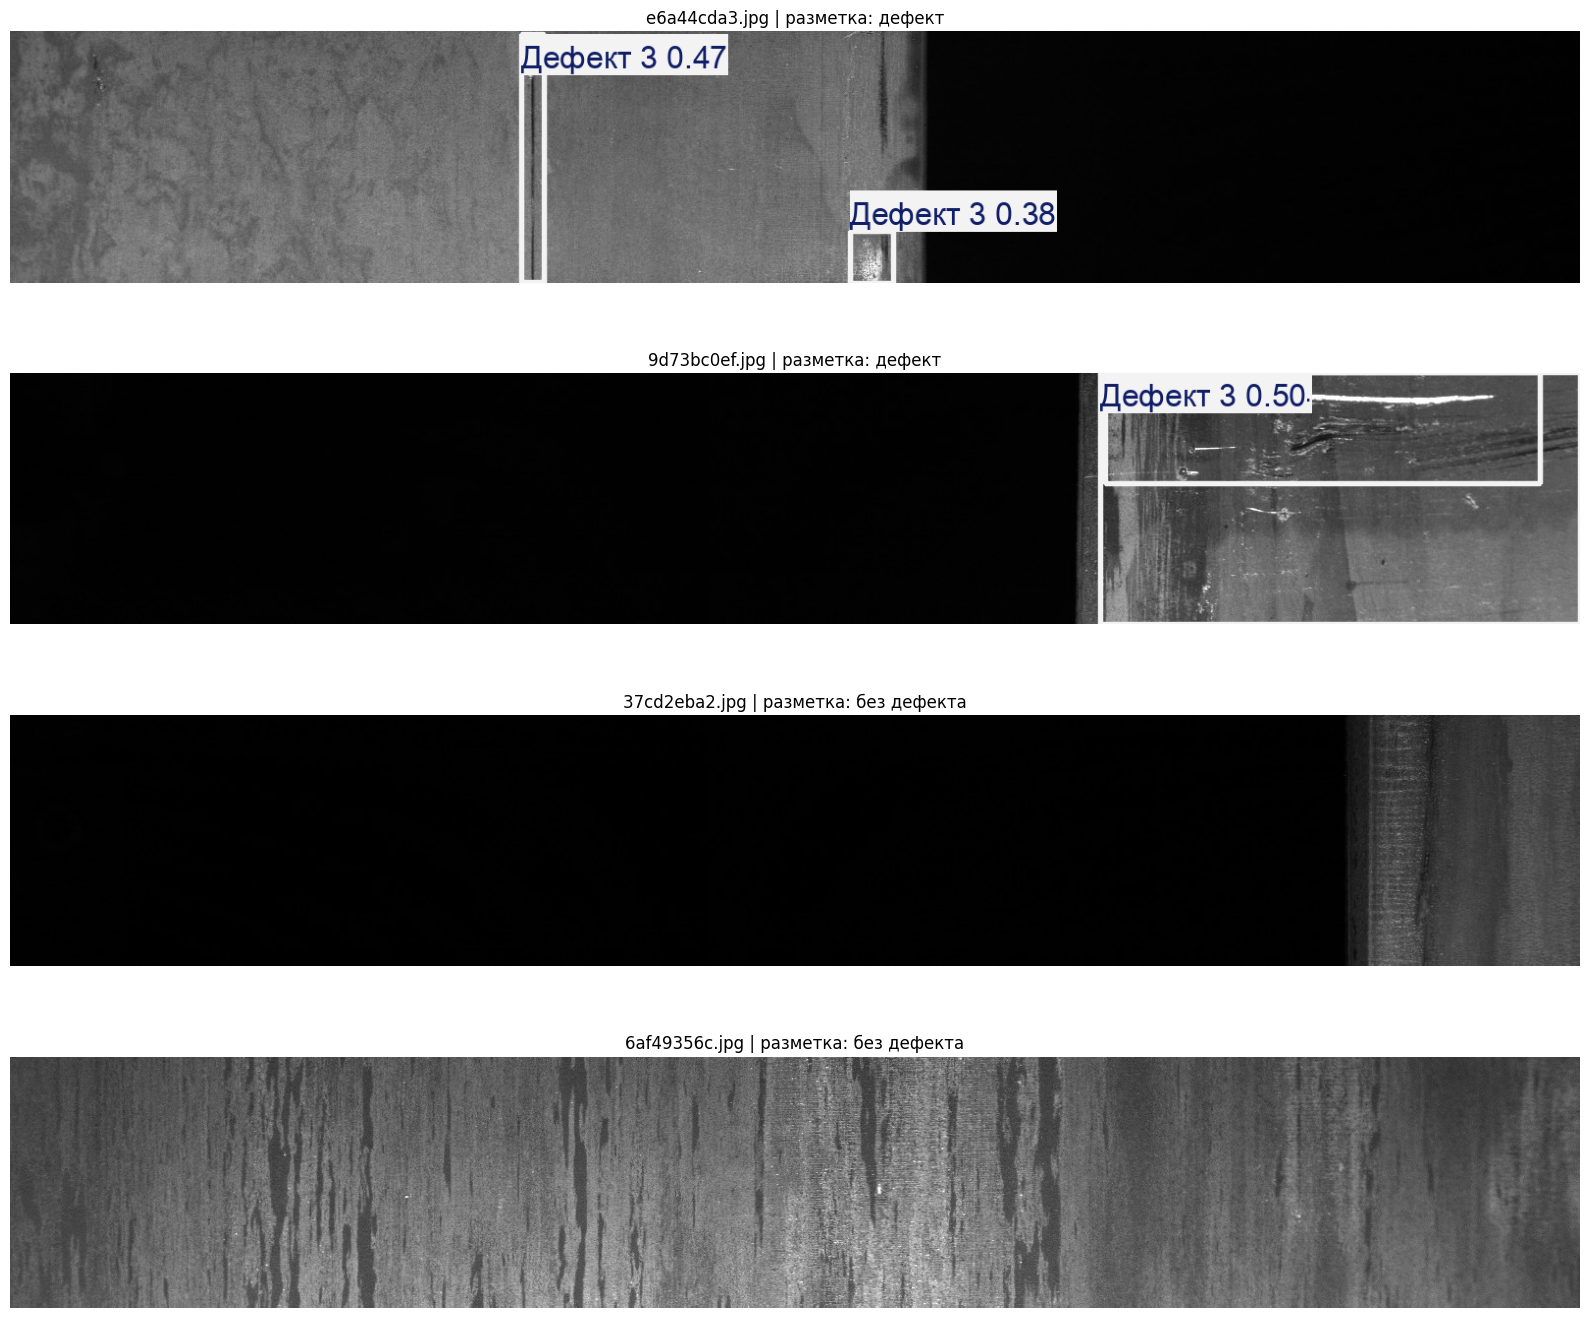

In [17]:
positive = [p for p in test_paths if p.name in by_image]
negative = [p for p in test_paths if p.name not in by_image]
demo_paths = positive[:2] + negative[:2]
fig, axes = plt.subplots(len(demo_paths), 1, figsize=(16, 3.5*len(demo_paths)))
for ax, path in zip(np.atleast_1d(axes), demo_paths):
    result = best_model.predict(str(path), imgsz=IMAGE_SIZE, conf=0.25, verbose=False)[0]
    ax.imshow(cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB))
    ax.set_title(f'{path.name} | разметка: {"дефект" if path.name in by_image else "без дефекта"}')
    ax.axis('off')
plt.tight_layout(); plt.show()


In [18]:
import gradio as gr

def predict_image(image, confidence):
    if image is None:
        return None, 'Загрузите изображение.'
    result = best_model.predict(image, imgsz=IMAGE_SIZE, conf=confidence,
                                verbose=False)[0]
    annotated = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)
    counts = np.bincount(result.boxes.cls.cpu().numpy().astype(int), minlength=4)
    report = '\n'.join(f'{CLASS_NAMES[i]}: {int(n)}' for i, n in enumerate(counts) if n)
    return annotated, report or 'Дефекты не обнаружены при выбранном пороге.'

def predict_video(video_path, confidence, max_frames):
    if not video_path:
        return None, 'Загрузите видео или запишите его с камеры.'
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        return None, 'Не удалось открыть видео.'
    fps = cap.get(cv2.CAP_PROP_FPS)
    if not np.isfinite(fps) or fps <= 0:
        fps = 25.0
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    if width <= 0 or height <= 0:
        cap.release()
        return None, 'Неверные размеры видео.'
    output_path = str(Path(tempfile.mkdtemp()) / 'detected.mp4')
    writer = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*'mp4v'),
                             fps, (width, height))
    if not writer.isOpened():
        cap.release()
        return None, 'Не удалось создать выходное MP4.'
    frames, total_boxes = 0, 0
    try:
        while frames < int(max_frames):
            ok, frame = cap.read()
            if not ok:
                break
            result = best_model.predict(frame, imgsz=IMAGE_SIZE, conf=confidence,
                                        verbose=False)[0]
            writer.write(result.plot())
            total_boxes += len(result.boxes)
            frames += 1
    finally:
        cap.release()
        writer.release()
    if not frames:
        return None, 'Видео не содержит доступных кадров.'
    return output_path, f'Обработано кадров: {frames}; обнаружено рамок: {total_boxes}'

with gr.Blocks(title='Дефекты стали — YOLO') as app:
    gr.Markdown('# Обнаружение дефектов поверхности стали\nЧетыре класса датасета Severstal; модель обучена в этом ноутбуке.')
    confidence = gr.Slider(0.05, 0.95, value=0.25, step=0.05,
                           label='Порог уверенности')
    with gr.Tab('Изображение'):
        img_input = gr.Image(type='numpy', label='Загрузить изображение')
        img_button = gr.Button('Найти дефекты')
        img_output = gr.Image(label='Результат')
        img_report = gr.Textbox(label='Сводка')
        img_button.click(predict_image, [img_input, confidence], [img_output, img_report])
    with gr.Tab('Видео / веб-камера'):
        video_input = gr.Video(sources=['upload', 'webcam'], label='Видео')
        max_frames = gr.Slider(30, 1500, value=300, step=30,
                               label='Максимум обрабатываемых кадров')
        video_button = gr.Button('Обработать видео')
        video_output = gr.Video(label='Результат')
        video_report = gr.Textbox(label='Сводка')
        video_button.click(predict_video, [video_input, confidence, max_frames],
                           [video_output, video_report])

# В Colab Gradio создаёт временную ссылку; пароль ограничивает доступ к GUI.
import secrets
gui_password = secrets.token_urlsafe(12)
print('Логин GUI: student')
print('Пароль GUI:', gui_password)
app.launch(share=True, inline=True, auth=('student', gui_password), show_error=True)


Логин GUI: student
Пароль GUI: j7h4Xh0r1yPY2HJu
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9921a6535b331a76aa.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 9. Выводы и рекомендации

После выполнения всех ячеек заполните вывод **своими полученными числами**:

1. Набор: ___ изображений; train/val/test = ___/___/___; четыре класса; готовые RLE-маски переведены в рамки связных областей.
2. Обучение: YOLO11n, ___ эпох (фактически), AdamW, `lr0=0.001`, batch ___, размер 640. По графикам train/val loss: ___; признаки переобучения: ___.
3. Тест: Precision ___, Recall ___, F1 ___, mAP@0.5 ___, mAP@0.5:0.95 ___. По PR/F1-кривым наиболее удачный порог уверенности: ___. AUC на уровне изображения по классам: ___.
4. Демонстрация GUI: на изображениях ___; на видео ___. Типичные ошибки: ___.
5. Метод применим для предварительного контроля и выделения подозрительных областей. Для точного контура, площади дефекта и сравнения с результатами конкурса рекомендуется обучать модель сегментации на исходных масках. Для промышленного применения нужны дополнительные снимки с другого оборудования и проверка устойчивости к освещению и смене партии стали.

**Источники:** [описание данных Kaggle](https://www.kaggle.com/competitions/severstal-steel-defect-detection/data), [документация Ultralytics по обучению](https://docs.ultralytics.com/modes/train/), [валидации и метрикам](https://docs.ultralytics.com/modes/val/), [Gradio Video](https://www.gradio.app/docs/gradio/video).


In [19]:
# Сохранение артефактов в Google Drive (по желанию).
# Раскомментируйте после завершения работы, чтобы не потерять best.pt и графики.
# from google.colab import drive
# drive.mount('/content/drive')
# shutil.copy2(BEST_WEIGHTS, '/content/drive/MyDrive/severstal_best.pt')
# shutil.make_archive('/content/drive/MyDrive/severstal_results', 'zip', RUN_DIR)
